John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

In [1]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [2]:
# load packages
install.packages("tidyverse")
library(tidyverse)
library(tidymodels)
theme_dark()
# set random seed
set.seed(42)

Installing package into 'C:/Users/johna/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'tidyverse' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\johna\AppData\Local\Temp\RtmpU5Cglo\downloaded_packages


Warning message:
"package 'tidyverse' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ─────────────────────

<theme> List of 144
 $ line                            : <ggplot2::element_line>
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ lineend      : chr "butt"
  ..@ linejoin     : chr "round"
  ..@ arrow        : logi FALSE
  ..@ arrow.fill   : chr "black"
  ..@ inherit.blank: logi TRUE
 $ rect                            : <ggplot2::element_rect>
  ..@ fill         : chr "white"
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ linejoin     : chr "round"
  ..@ inherit.blank: logi TRUE
 $ text                            : <ggplot2::element_text>
  ..@ family       : chr ""
  ..@ face         : chr "plain"
  ..@ italic       : chr NA
  ..@ fontweight   : num NA
  ..@ fontwidth    : num NA
  ..@ colour       : chr "black"
  ..@ size         : num 11
  ..@ hjust        : num 0.5
  ..@ vjust        : num 0.5
  ..@ angle        : num 0
  ..@ lineheight   : num 0.9
  ..@ margin       : <ggplot2::margin> nu

In [3]:
test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

test_accuracies <- bind_rows(test_accuracies)
song_accuracies <- bind_rows(song_accuracies)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs since last own song_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (44 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes All songs since last own song_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes Baseline Classifier_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [4]:
test_accuracies <- song_accuracies %>% group_by(ID) %>% summarize(repertoire_size = n_distinct(UST)) %>% 
    full_join(test_accuracies, by=join_by(ID)) %>%
    full_join(focal_males, by=join_by(ID))

Warning message in full_join(., focal_males, by = join_by(ID)):
"Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 5 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning."


In [5]:
test_accuracies %>% pull(model) %>% unique()

[1] "All songs in last 60s"                                     
 [2] "All songs since last own song"                             
 [3] "Attention 30s"                                             
 [4] "Attention"                                                 
 [5] "Baseline Classifier"                                       
 [6] "Most Common Songs No Own History"                          
 [7] "Most Common Songs"                                         
 [8] "N greater than 30 Baseline Classifier"                     
 [9] "Own Last Songs"                                            
[10] "Own Song History"                                          
[11] "Song types N greater than 30 All songs since last own song"
[12] "Top 5 Classes All songs since last own song"               
[13] "Top 5 Classes Baseline Classifier"                         
[14] "Last Song from Each Neighbour"                             
[15] "Hierarchical Classifier All songs since last own song"

In [6]:
report_models <- c(
    "Baseline Classifier",
    "Own Song History",
    "Own Last Songs",
    "Last Song from Each Neighbour",
    "All songs since last own song",
    "All songs in last 60s",
    "Attention",
    "Attention 30s",
    "Most Common Songs"
)

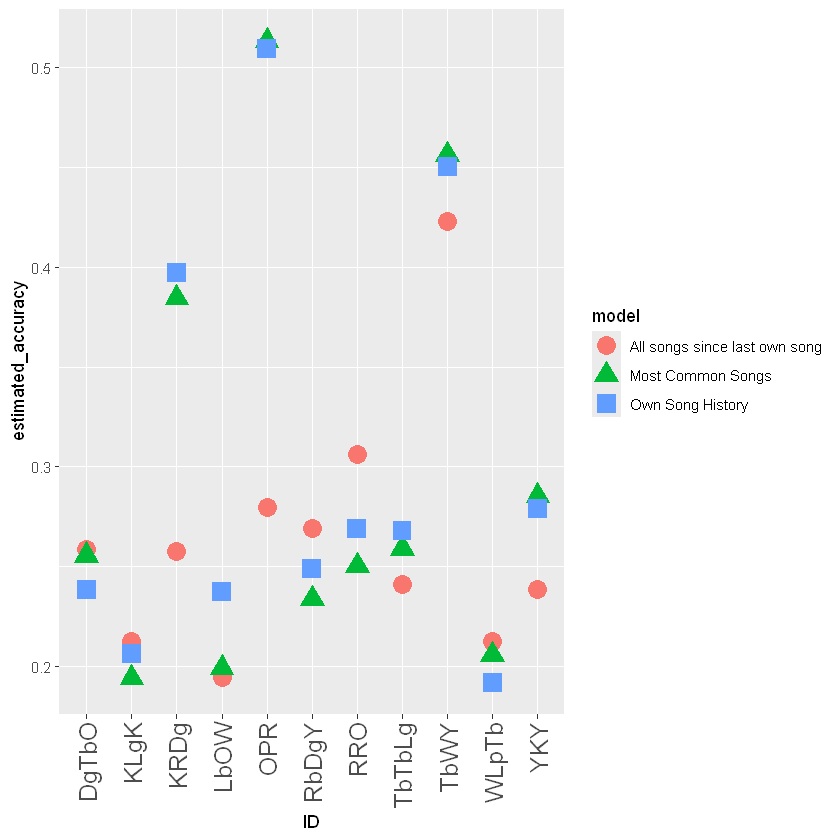

In [7]:
# TODO: Throw in baseline classifer
plot <- ggplot(data = test_accuracies %>% filter(model %in% c("Own Song History", "Most Common Songs", 'All songs since last own song')), aes(x=ID, y=estimated_accuracy, color=model, shape=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical
print(plot)

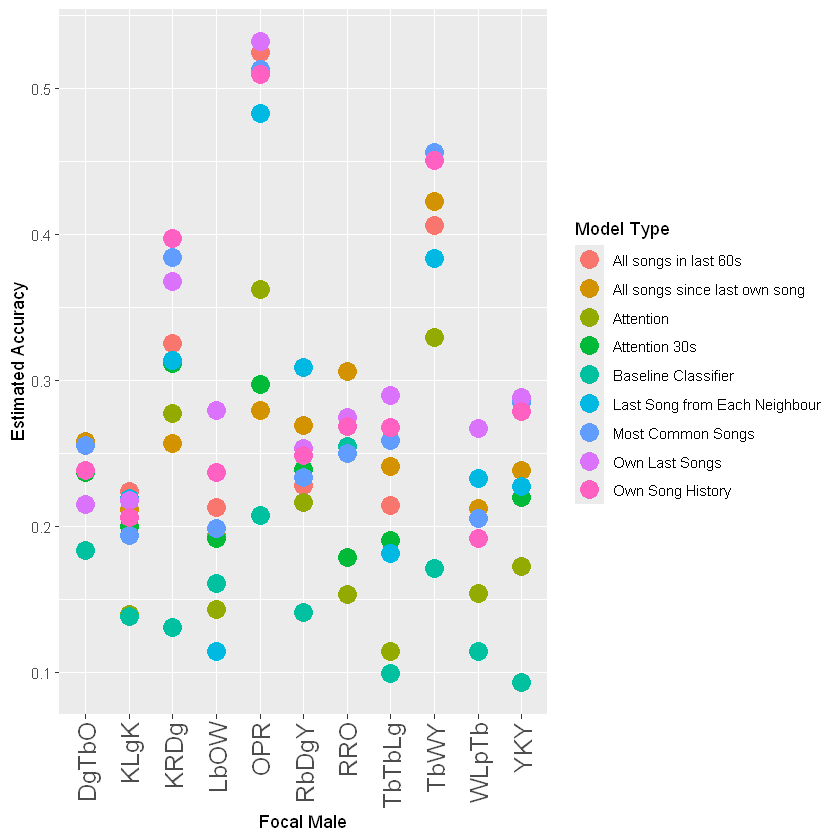

In [8]:
# TODO: Throw in baseline classifer
plot <- ggplot(data = test_accuracies %>% filter(model %in% report_models), aes(x=ID, y=estimated_accuracy, color=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Focal Male", y= "Estimated Accuracy", colour="Model Type")
print(plot)

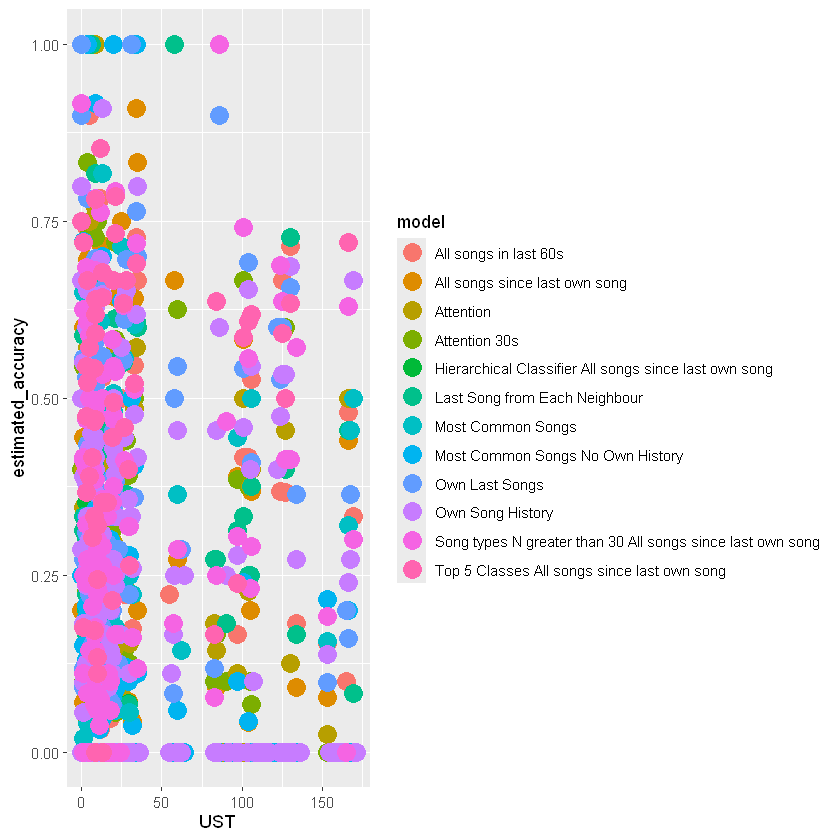

In [9]:

plot <- ggplot(data = song_accuracies, aes(x=UST, y=estimated_accuracy, color=model)) +
    geom_point(size=5)
print(plot)

Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 12 values. Consider specifying shapes manually if you need
  that many of them."
Warning message:
"Removed 1388 rows containing missing values or values outside the scale range
(`geom_point()`)."


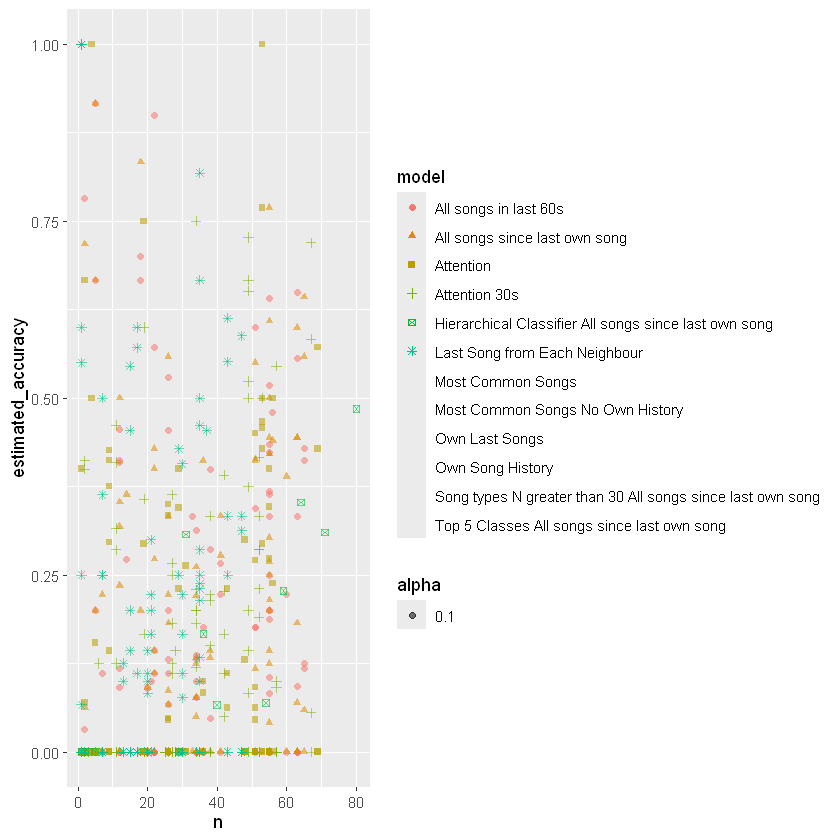

In [10]:
plot <- ggplot(data=song_accuracies) + 
    aes(x=n, y=estimated_accuracy, color=model, shape=model, alpha=0.1) +
    geom_point()
print(plot)

Ignoring unknown labels:
• colour : "Focal Male"


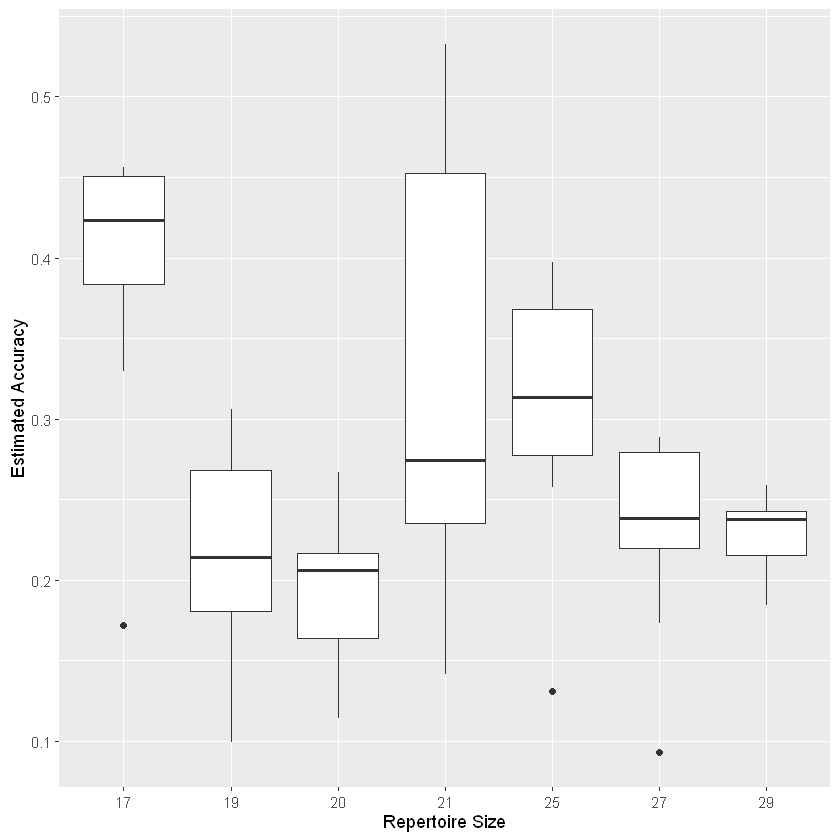

In [41]:
ggplot(test_accuracies %>% filter(model %in% report_models) %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
    geom_boxplot() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male')

Ignoring unknown labels:
• colour : "Focal Male"


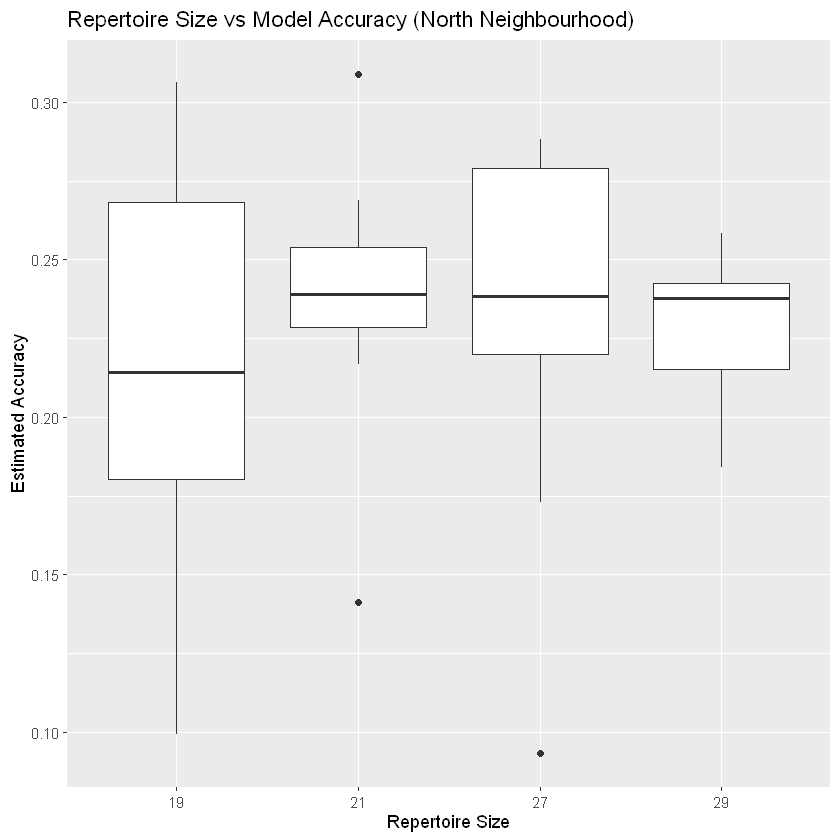

In [40]:
ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "north") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
    geom_boxplot() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (North Neighbourhood)")

Ignoring unknown labels:
• colour : "Focal Male"


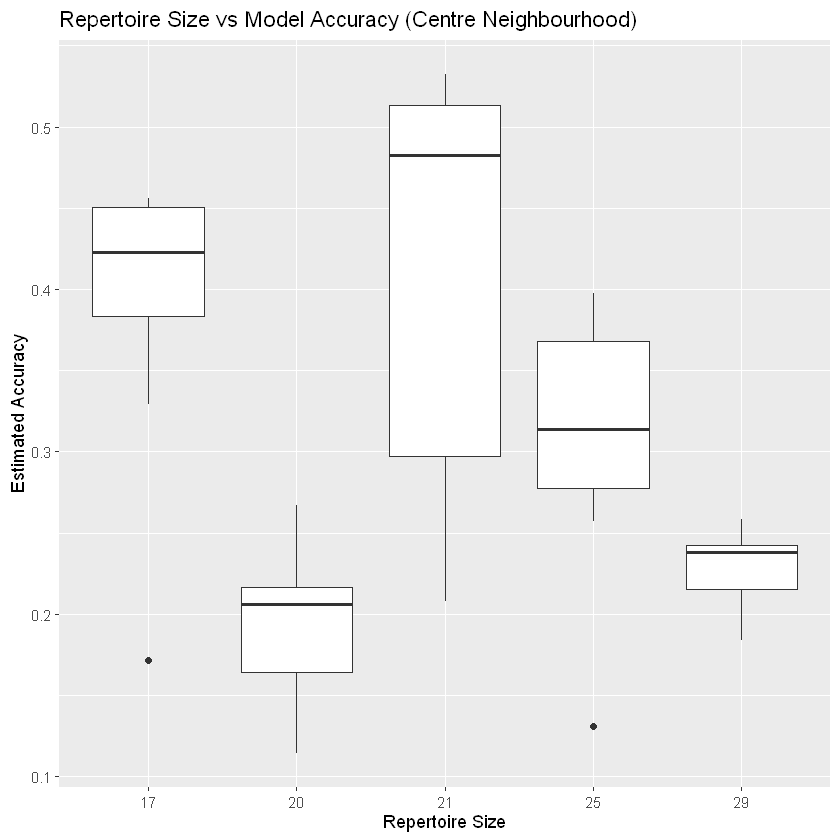

In [42]:
ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "centre") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
    geom_boxplot() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (Centre Neighbourhood)")

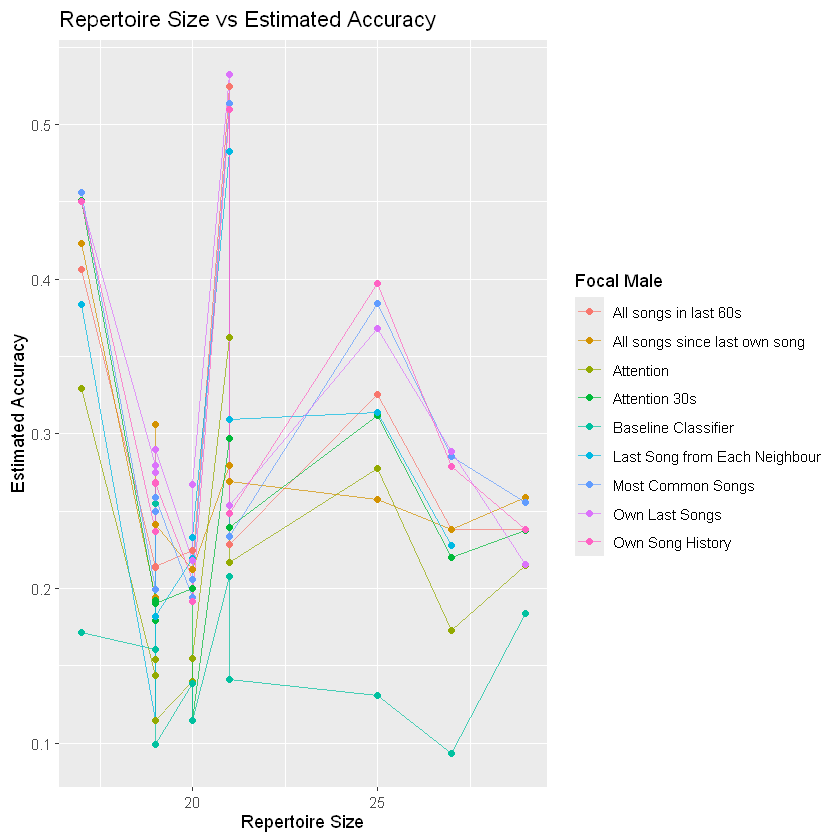

In [43]:
ggplot(test_accuracies %>% filter(model %in% report_models), aes(x=repertoire_size, y=estimated_accuracy, color=model)) +
    geom_line( alpha=0.7) +
    geom_point() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Estimated Accuracy")

In [13]:
song_accuracies

ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,33,0.54700855,All songs in last 60s,NA
DgTbO,25,0.50000000,All songs in last 60s,NA
DgTbO,20,0.45588235,All songs in last 60s,12
DgTbO,7,0.27419355,All songs in last 60s,NA
DgTbO,32,0.17391304,All songs in last 60s,NA
DgTbO,153,0.15384615,All songs in last 60s,NA
DgTbO,10,0.13684211,All songs in last 60s,34
DgTbO,1,0.09302326,All songs in last 60s,63
DgTbO,8,0.08219178,All songs in last 60s,55


In [14]:
unique(song_accuracies$model)

[1] "All songs in last 60s"                                     
 [2] "All songs since last own song"                             
 [3] "Attention 30s"                                             
 [4] "Attention"                                                 
 [5] "Hierarchical Classifier All songs since last own song"     
 [6] "Last Song from Each Neighbour"                             
 [7] "Most Common Songs No Own History"                          
 [8] "Most Common Songs"                                         
 [9] "Own Last Songs"                                            
[10] "Own Song History"                                          
[11] "Song types N greater than 30 All songs since last own song"
[12] "Top 5 Classes All songs since last own song"

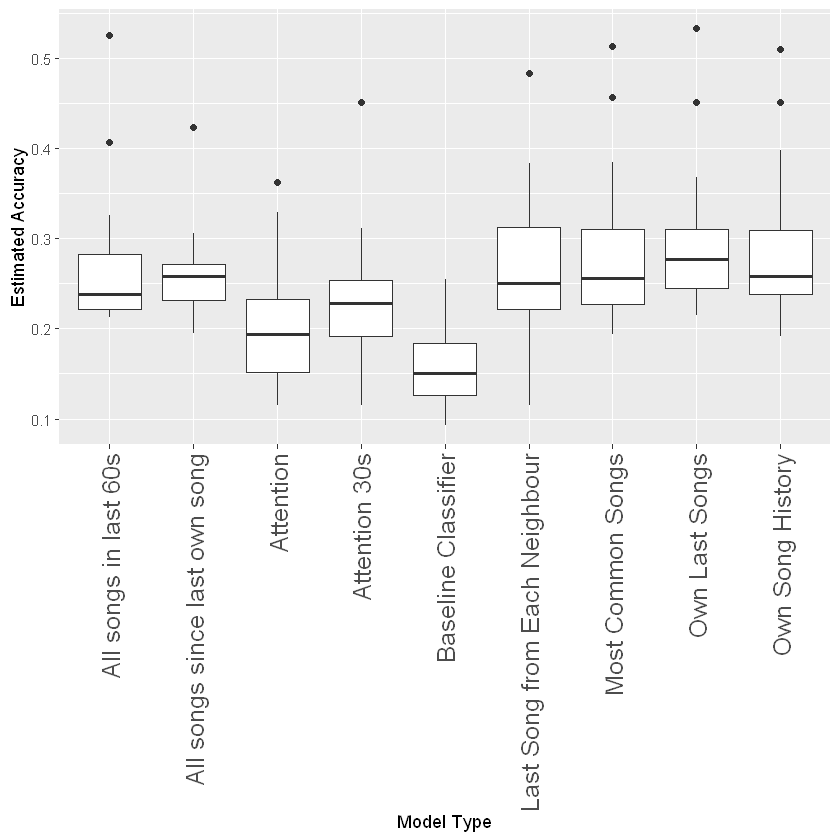

In [15]:
# Accuracy distribution of each model type
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical 
    labs(x="Model Type", y="Estimated Accuracy")

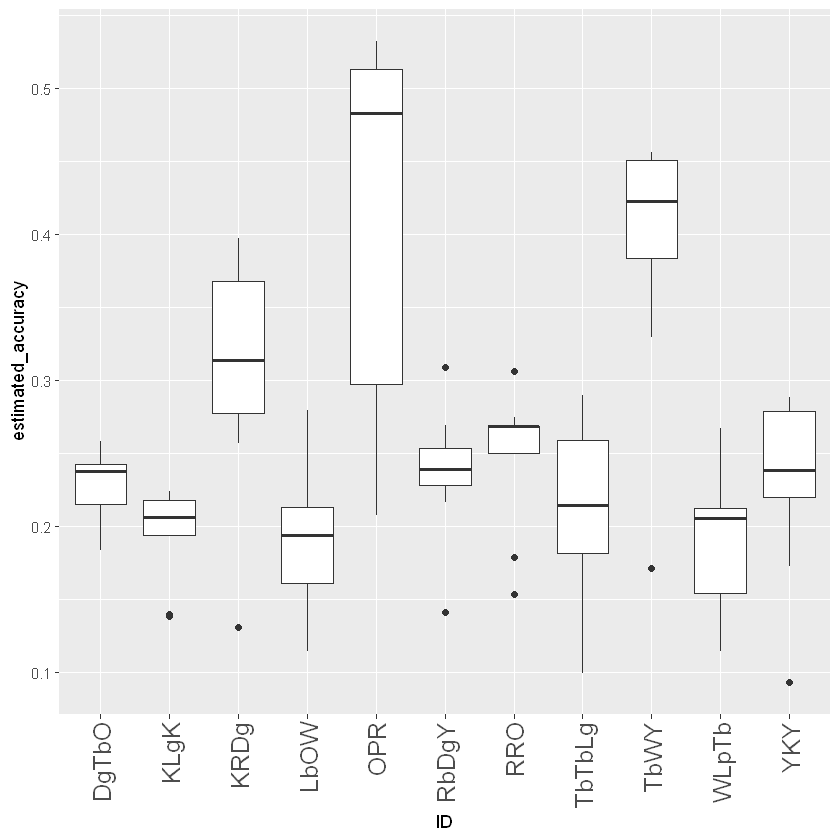

In [16]:
# Accuracy distribution of each focal male
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=ID, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

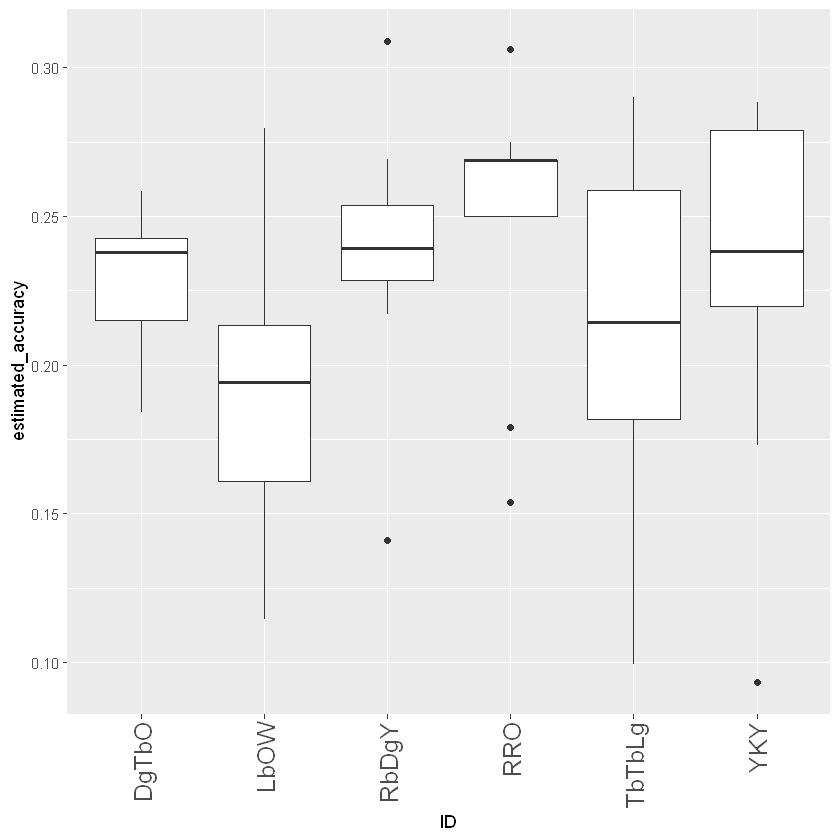

In [25]:
# Accuracy distribution of each focal male
ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="north")) +
    aes(x=ID, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

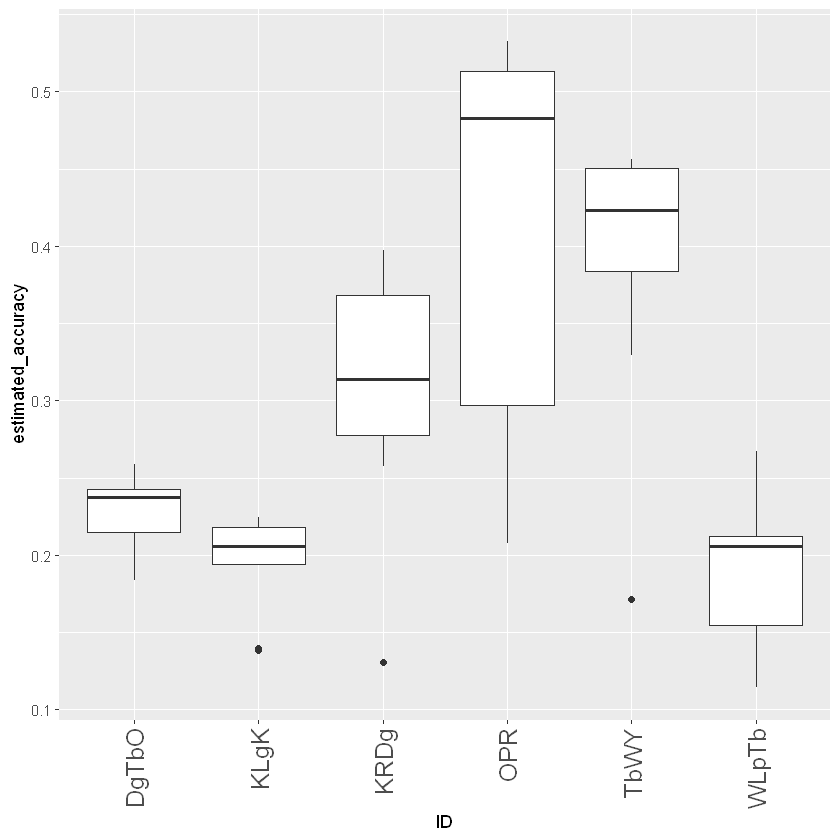

In [ ]:
# Accuracy distribution of each focal male
ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="centre")) +
    aes(x=ID, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

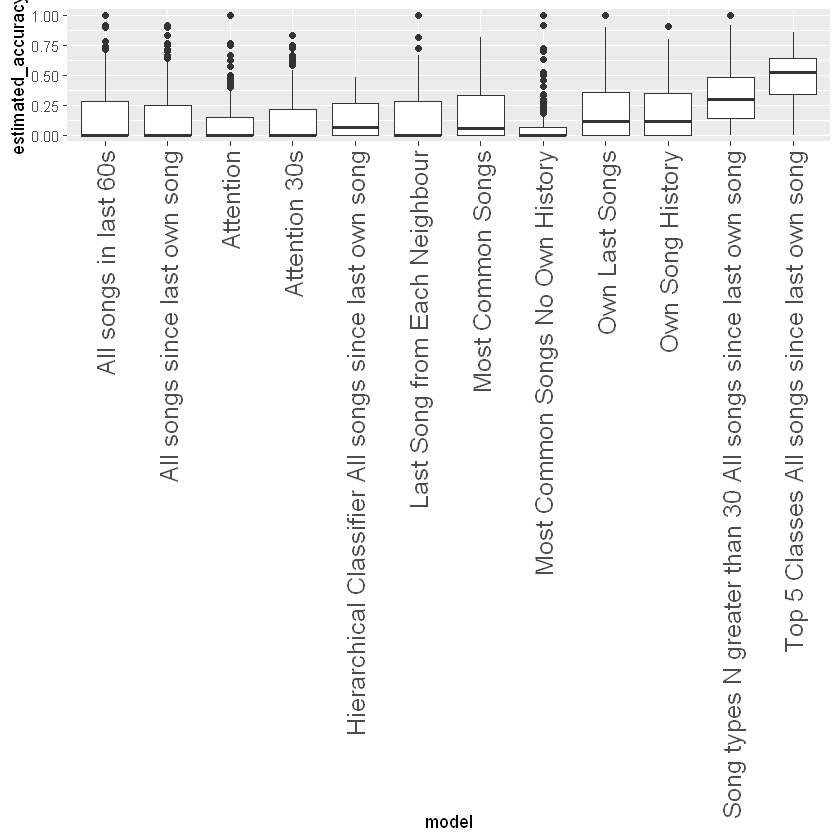

In [17]:
# Accuracy distribution of song types according to models
ggplot(data=song_accuracies) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [18]:
ggplot(data=test_accuracies) +
    geom_bar(aes(x=ID, y=estimated_accuracy))

ERROR while rich displaying an object: Error in `geom_bar()`:
! Problem while computing stat.
ℹ Error occurred in the 1st layer.
Caused by error in `setup_params()`:
! `stat_count()` must only have an x or y aesthetic.

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mim

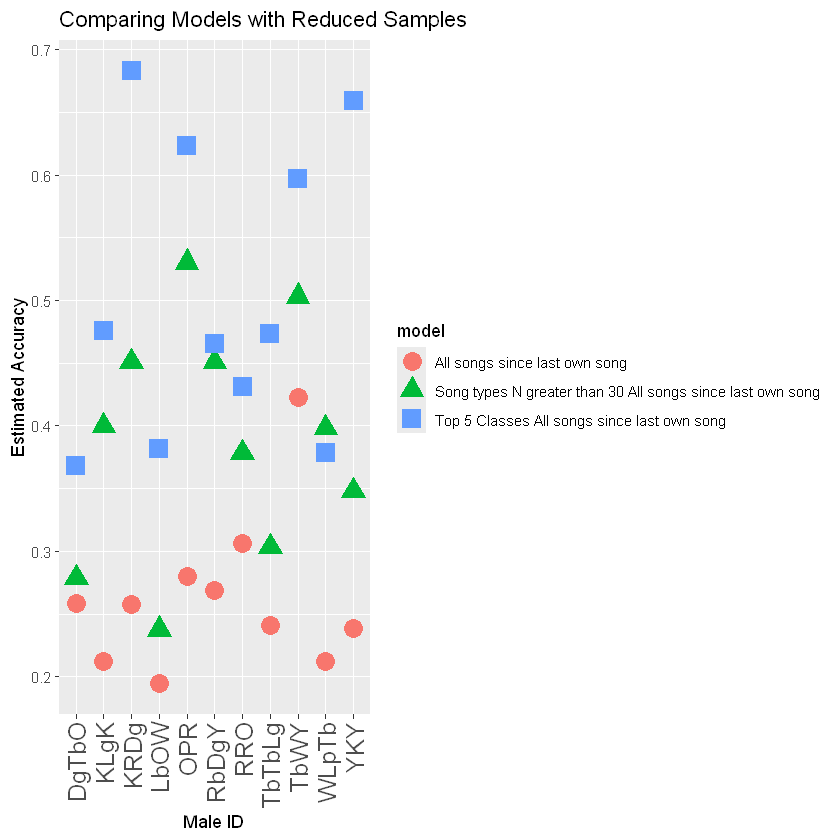

In [19]:
plot <- ggplot(data = test_accuracies %>% filter(model %in% c("All songs since last own song", "Top 5 Classes All songs since last own song", "Song types N greater than 30 All songs since last own song")), aes(x=ID, y=estimated_accuracy, color=model, shape=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Male ID", y="Estimated Accuracy", title="Comparing Models with Reduced Samples")
print(plot)

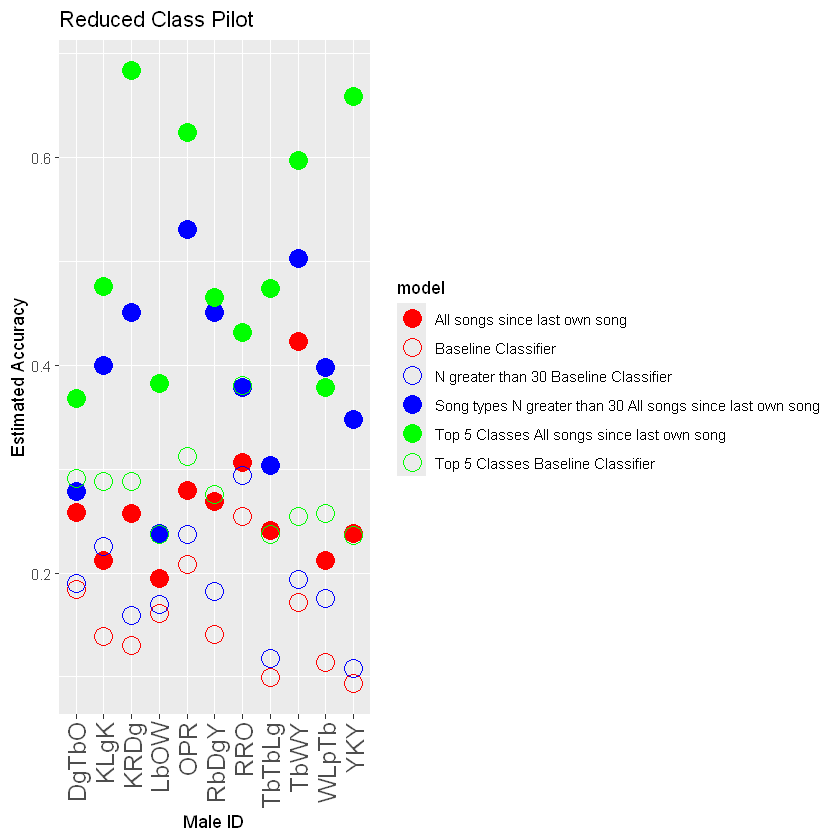

In [20]:
reduced_sample_models <- c("All songs since last own song", "Top 5 Classes All songs since last own song", "Song types N greater than 30 All songs since last own song")
baseline_classifiers <- c("Baseline Classifier", "Top 5 Classes Baseline Classifier", "N greater than 30 Baseline Classifier")
colours <- c(
  "All songs since last own song" = "red",
  "Top 5 Classes All songs since last own song" = "green",
  "Song types N greater than 30 All songs since last own song" = "blue",
  
  # Baseline Counterparts (mapping to the same colors)
  "Baseline Classifier" = "red",
  "Top 5 Classes Baseline Classifier" = "green",
  "N greater than 30 Baseline Classifier" = "blue"
)

plot <- ggplot() +
    geom_point(data = test_accuracies %>% filter(model %in% reduced_sample_models), aes(x=ID, y=estimated_accuracy, color=model), size=5) +
    geom_point(data = test_accuracies %>% filter(model %in% baseline_classifiers), aes(x=ID, y=estimated_accuracy, color=model), shape=1, size=5) + 
    scale_color_manual(values = colours) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Male ID", y="Estimated Accuracy", title="Reduced Class Pilot")
print(plot)

In [21]:
reduced_sample_models <- c("All songs since last own song", "Top 5 Classes All songs since last own song", "Song types N greater than 30 All songs since last own song")
baseline_classifiers <- c("Baseline Classifier", "Top 5 Classes Baseline Classifier", "N greater than 30 Baseline Classifier")
 corresponding_models <- c(
    "All songs since last own song" = "Baseline Classifier",
    "Top 5 Classes All songs since last own song" = "Top 5 Classes Baseline Classifier",
    "Song types N greater than 30 All songs since last own song" = "N greater than 30 Baseline Classifier"
) 

x_labels <- c(
  "All songs since last own song" = "All Songs",
  "Top 5 Classes All songs since last own song" = "Top 5",
  "Song types N greater than 30 All songs since last own song" = "N > 30"
)

accuracy_improvement <- test_accuracies %>%
  filter(model %in% reduced_sample_models) %>%
  rowwise() %>%
  mutate(
    # Look up the baseline model name from your vector
    baseline_name = corresponding_models[model],
    
    # Extract the baseline value for the current ID
    baseline_val = test_accuracies$estimated_accuracy[
      test_accuracies$ID == ID & test_accuracies$model == baseline_name
    ],
    
    # Calculate the gain
    accuracy_gain = estimated_accuracy - baseline_val
  ) %>%
  ungroup()


plot <- ggplot(data=accuracy_improvement) +
    geom_boxplot(aes(x=model, y=accuracy_gain)) +
    labs(x="Model Type", y = "Accuracy Gain from Baseline Classifier") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical 
    scale_x_discrete(labels=x_labels)

print(plot)

ERROR: [1m[33mError[39m in `mutate()`:[22m
[1m[22m[36mℹ[39m In argument: `baseline_val = ...[]`.
[36mℹ[39m In row 1.
[1mCaused by error:[22m
[1m[22m[33m![39m `baseline_val` must be size 1, not 2.
[36mℹ[39m Did you mean: `baseline_val = list(...[])` ?


In [ ]:
accuracy_improvement

ID,repertoire_size,estimated_accuracy,model,baseline_name,baseline_val,accuracy_gain
<chr>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
DgTbO,29,0.2585139,All songs since last own song,Baseline Classifier,0.18395574,0.07455819
DgTbO,29,0.2786624,Song types N greater than 30 All songs since last own song,N greater than 30 Baseline Classifier,0.19000000,0.08866242
DgTbO,29,0.3682927,Top 5 Classes All songs since last own song,Top 5 Classes Baseline Classifier,0.29060452,0.07768817
KLgK,20,0.2121212,All songs since last own song,Baseline Classifier,0.13848921,0.07363200
KLgK,20,0.4000000,Song types N greater than 30 All songs since last own song,N greater than 30 Baseline Classifier,0.22580645,0.17419355
KLgK,20,0.4756098,Top 5 Classes All songs since last own song,Top 5 Classes Baseline Classifier,0.28838951,0.18722024
KRDg,25,0.2573290,All songs since last own song,Baseline Classifier,0.13068732,0.12664167
KRDg,25,0.4509804,Song types N greater than 30 All songs since last own song,N greater than 30 Baseline Classifier,0.15882353,0.29215686
KRDg,25,0.6830986,Top 5 Classes All songs since last own song,Top 5 Classes Baseline Classifier,0.28846154,0.39463705


In [48]:
test_accuracies %>% group_by(ID) %>% summarize(mean_accuracy = mean(estimated_accuracy)) %>% arrange(desc(mean_accuracy))

ID,mean_accuracy
<chr>,<dbl>
OPR,0.4023518
TbWY,0.3742354
KRDg,0.3216006
RRO,0.2807270
RbDgY,0.2628678
YKY,0.2492681
DgTbO,0.2422351
KLgK,0.2346578
TbTbLg,0.2202161


In [ ]:
test_accuracies %>% group_by(model) %>% summarize(mean_accuracy = mean)

ID,repertoire_size,estimated_accuracy,model,neighbourhood,male_number
<chr>,<int>,<dbl>,<chr>,<chr>,<chr>
DgTbO,29,0.2383901,All songs in last 60s,north,5
DgTbO,29,0.2383901,All songs in last 60s,centre,6
DgTbO,29,0.2585139,All songs since last own song,north,5
DgTbO,29,0.2585139,All songs since last own song,centre,6
DgTbO,29,0.2371795,Attention 30s,north,5
DgTbO,29,0.2371795,Attention 30s,centre,6
DgTbO,29,0.2150313,Attention,north,5
DgTbO,29,0.2150313,Attention,centre,6
DgTbO,29,0.1839557,Baseline Classifier,north,5
